11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Testing images: (10000, 28, 28)


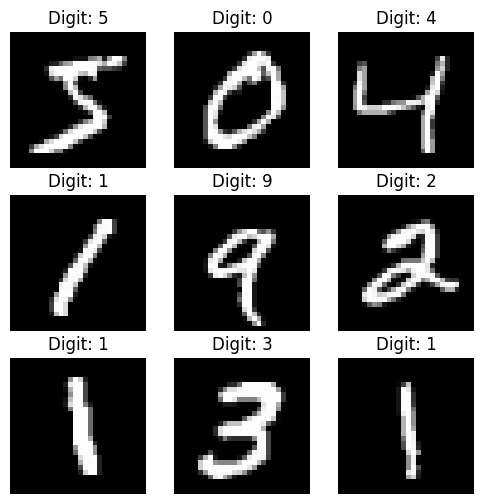

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 5408)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     1,384,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,387,594 (5.29 MB)

 Trainable params: 1,387,594 (5.29 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 39s 75ms/step - accuracy: 0.7795 - loss: 0.9419 - val_accuracy: 0.8988 - val_loss: 0.3660
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 40s 74ms/step - accuracy: 0.9055 - loss: 0.3318 - val_accuracy: 0.9172 - val_loss: 0.2859
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 39s 70ms/step - accuracy: 0.9198 - loss: 0.2778 - val_accuracy: 0.9307 - val_loss: 0.2432
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 35s 75ms/step - accuracy: 0.9295 - loss: 0.2448 - val_accuracy: 0.9398 - val_loss: 0.2161
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 33s 70ms/step - accuracy: 0.9364 - loss: 0.2201 - val_accuracy: 0.9436 - val_loss: 0.1985
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 34s 72ms/step - accuracy: 0.9421 - loss: 0.1995 - val_accuracy: 0.9501 - val_loss: 0.1805
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 33s 69ms/step - accuracy: 0.9468 - loss: 0.1826 - val_accuracy: 0.9520 - val_loss: 0.1660
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 41s 70ms/step - accuracy: 0.9511 - loss: 0.1679 - 

The model has successfully trained.
Model saved as mnist_digit_recognizer.h5
Test Loss: 0.13891908526420593
Test Accuracy: 0.9609000086784363


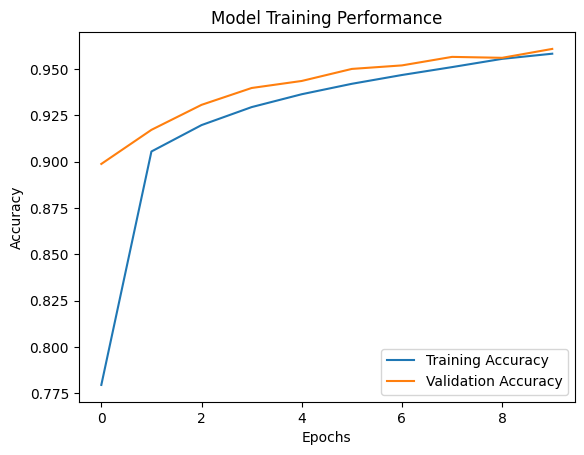

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step
Image 1 - Predicted: 7 | Actual: 7
Image 2 - Predicted: 2 | Actual: 2
Image 3 - Predicted: 1 | Actual: 1
Image 4 - Predicted: 0 | Actual: 0
Image 5 - Predicted: 4 | Actual: 4
Image 6 - Predicted: 1 | Actual: 1
Image 7 - Predicted: 4 | Actual: 4
Image 8 - Predicted: 9 | Actual: 9
Image 9 - Predicted: 6 | Actual: 5
Image 10 - Predicted: 9 | Actual: 9


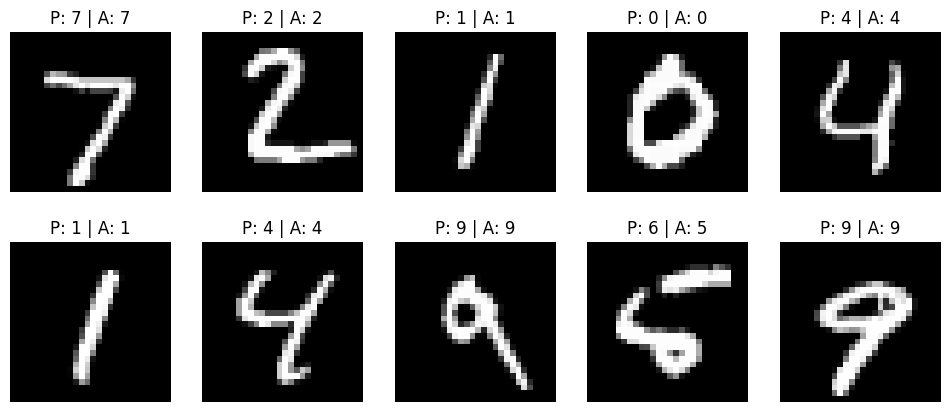

In [1]:
# Assignment: Train, evaluate, and recognize handwritten digits

import numpy as np
import matplotlib.pyplot as plt

from keras.datasets import mnist
from keras.models import Sequential, load_model
from keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.optimizers import SGD
from tensorflow.keras.preprocessing.image import load_img, img_to_array

# Step 1: Load the MNIST dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()
print("Training images:", x_train.shape)
print("Testing images:", x_test.shape)

# Step 2: Display sample digits
plt.figure(figsize=(6, 6))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title("Digit: " + str(y_train[i]))
    plt.axis("off")
plt.show()

# Step 3: Preprocess the data
x_train = x_train.reshape(x_train.shape[0], 28, 28, 1).astype("float32") / 255
x_test = x_test.reshape(x_test.shape[0], 28, 28, 1).astype("float32") / 255

y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)
input_shape = (28, 28, 1)

# Step 4: Build and compile the CNN model
model = Sequential([
    Conv2D(32, kernel_size=(3, 3), activation="relu", input_shape=input_shape),
    MaxPooling2D(pool_size=(2, 2)),
    Flatten(),
    Dense(256, activation="relu"),
    Dense(10, activation="softmax")
])

optimizer = SGD(learning_rate=0.01)
model.compile(loss="categorical_crossentropy", optimizer=optimizer, metrics=["accuracy"])
model.summary()

# Step 5: Train the model
history = model.fit(
    x_train, y_train,
    batch_size=128,
    epochs=10,
    validation_data=(x_test, y_test)
)
print("The model has successfully trained.")

# Step 6: Save and evaluate the model
model.save("mnist_digit_recognizer.h5")
print("Model saved as mnist_digit_recognizer.h5")

test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

# Step 7: Plot training performance
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Training Performance")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

# Step 8: Recognize digits from test images
saved_model = load_model("mnist_digit_recognizer.h5")
predictions = saved_model.predict(x_test)

plt.figure(figsize=(12, 5))
for i in range(10):
    predicted_digit = np.argmax(predictions[i])
    actual_digit = np.argmax(y_test[i])
    print("Image", i + 1, "- Predicted:", predicted_digit, "| Actual:", actual_digit)
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap="gray")
    plt.title("P: " + str(predicted_digit) + " | A: " + str(actual_digit))
    plt.axis("off")
plt.show()

# Step 9: Optional custom image prediction
def predict_custom_digit(image_path):
    img = load_img(image_path, color_mode="grayscale", target_size=(28, 28))
    img = img_to_array(img).reshape(1, 28, 28, 1).astype("float32") / 255
    prediction = saved_model.predict(img)
    print("Predicted digit:", np.argmax(prediction))

# Example: Place sample_image.png in the same folder, then run:
# predict_custom_digit("sample_image.png")
